In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

In [11]:
df = pd.read_csv('airline-passengers.csv')

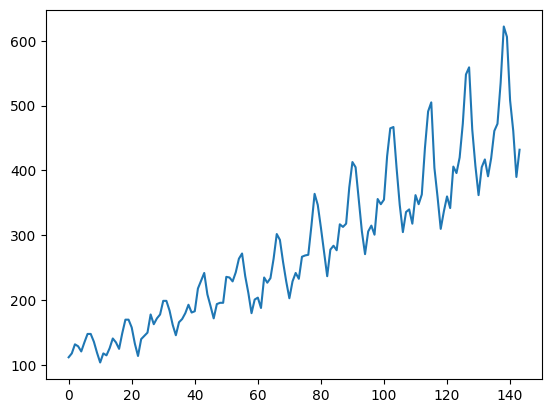

In [12]:
timeseries = df[["Passengers"]].values.astype('float32')
plt.plot(timeseries)
plt.show()

In [15]:
# train-test split for time series
train_size = int(len(timeseries) * 0.67)
test_size = len(timeseries) - train_size
train, test = timeseries[:train_size], timeseries[train_size:]

In [16]:
def create_dataset(dataset, lookback):
    """Transform a time series into a prediction dataset
    Args:
    dataset: A numpy array of time series, first dimension is the time steps
    lookback: Size of window for prediction
    """
    X, y = [], []
    for i in range(len(dataset)-lookback):
        feature = dataset[i:i+lookback]
        target = dataset[i+1:i+lookback+1]
        X.append(feature)
        y.append(target)
    return torch.tensor(X), torch.tensor(y)

In [17]:
lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([95, 1, 1]) torch.Size([95, 1, 1])
torch.Size([47, 1, 1]) torch.Size([47, 1, 1])


C:\Users\Villette\AppData\Local\Temp\ipykernel_8072\2760436764.py:13: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  return torch.tensor(X), torch.tensor(y)


In [18]:
class AirModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=50, num_layers=1, batch_first=True)
        self.linear = nn.Linear(50, 1)
    def forward(self, x):
        x, _ = self.lstm(x)
        x = self.linear(x)
        return x

In [19]:
model = AirModel()
optimizer = optim.Adam(model.parameters())
loss_fn = nn.MSELoss()
loader = data.DataLoader(data.TensorDataset(X_train, y_train), shuffle=True, batch_size=8)

n_epochs = 2000
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    if epoch % 100 != 0:
        continue
    model.eval()
    with torch.no_grad():
        y_pred = model(X_train)
        train_rmse = np.sqrt(loss_fn(y_pred, y_train))
        y_pred = model(X_test)
        test_rmse = np.sqrt(loss_fn(y_pred, y_test))
    print("Epoch %d: train RMSE %.4f, test RMSE %.4f" % (epoch, train_rmse, test_rmse))

C:\Users\Villette\AppData\Local\Temp\ipykernel_8072\647027190.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  train_rmse = np.sqrt(loss_fn(y_pred, y_train))
C:\Users\Villette\AppData\Local\Temp\ipykernel_8072\647027190.py:23: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  test_rmse = np.sqrt(loss_fn(y_pred, y_test))


Epoch 0: train RMSE 225.9575, test RMSE 422.3553
Epoch 100: train RMSE 187.1945, test RMSE 381.8151
Epoch 200: train RMSE 154.8557, test RMSE 347.0216
Epoch 300: train RMSE 126.8322, test RMSE 315.3724
Epoch 400: train RMSE 103.4649, test RMSE 286.4958
Epoch 500: train RMSE 85.1585, test RMSE 260.5575
Epoch 600: train RMSE 68.7031, test RMSE 235.6448
Epoch 700: train RMSE 55.8030, test RMSE 212.6100
Epoch 800: train RMSE 45.6511, test RMSE 191.8135
Epoch 900: train RMSE 38.7608, test RMSE 173.6388
Epoch 1000: train RMSE 33.4263, test RMSE 157.4369
Epoch 1100: train RMSE 29.8016, test RMSE 144.4006
Epoch 1200: train RMSE 28.8816, test RMSE 134.4958
Epoch 1300: train RMSE 26.0299, test RMSE 125.3555
Epoch 1400: train RMSE 25.8631, test RMSE 117.9068
Epoch 1500: train RMSE 24.5451, test RMSE 113.6793
Epoch 1600: train RMSE 24.0662, test RMSE 109.3494
Epoch 1700: train RMSE 23.9409, test RMSE 106.3293
Epoch 1800: train RMSE 23.9585, test RMSE 104.4355
Epoch 1900: train RMSE 23.8796, test R

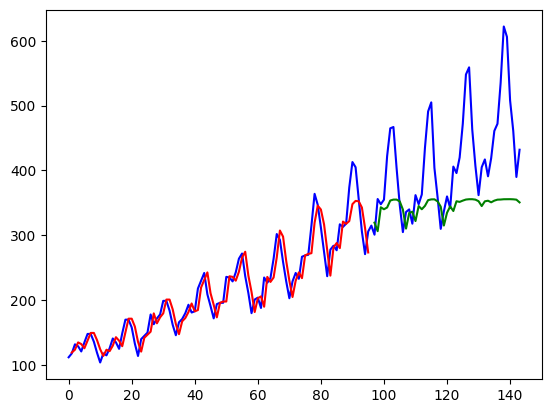

In [20]:
with torch.no_grad():
    # shift train predictions for plotting
    train_plot = np.ones_like(timeseries) * np.nan
    y_pred = model(X_train)
    y_pred = y_pred[:, -1, :]
    train_plot[lookback:train_size] = model(X_train)[:, -1, :]
    # shift test predictions for plotting
    test_plot = np.ones_like(timeseries) * np.nan
    test_plot[train_size+lookback:len(timeseries)] = model(X_test)[:, -1, :]
# plot
plt.plot(timeseries, c='b')
plt.plot(train_plot, c='r')
plt.plot(test_plot, c='g')
plt.show()

In [21]:
lookback = 4
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)

C:\Users\Villette\AppData\Local\Temp\ipykernel_8072\3437425327.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  train_rmse = np.sqrt(loss_fn(y_pred, y_train))
C:\Users\Villette\AppData\Local\Temp\ipykernel_8072\3437425327.py:23: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  test_rmse = np.sqrt(loss_fn(y_pred, y_test))


Epoch 0: train RMSE 226.0412, test RMSE 425.2890
Epoch 100: train RMSE 174.8978, test RMSE 371.5792
Epoch 200: train RMSE 136.5898, test RMSE 329.4027
Epoch 300: train RMSE 106.2787, test RMSE 292.6148
Epoch 400: train RMSE 82.5778, test RMSE 258.8843
Epoch 500: train RMSE 63.0798, test RMSE 227.1015
Epoch 600: train RMSE 49.6203, test RMSE 199.8978
Epoch 700: train RMSE 40.1402, test RMSE 176.2149
Epoch 800: train RMSE 33.6249, test RMSE 155.6719
Epoch 900: train RMSE 29.2173, test RMSE 138.0745
Epoch 1000: train RMSE 26.3131, test RMSE 123.7926
Epoch 1100: train RMSE 24.3708, test RMSE 112.4089
Epoch 1200: train RMSE 23.0934, test RMSE 103.4459
Epoch 1300: train RMSE 22.1353, test RMSE 96.4309
Epoch 1400: train RMSE 21.8209, test RMSE 90.9323
Epoch 1500: train RMSE 20.9509, test RMSE 86.1222
Epoch 1600: train RMSE 20.5267, test RMSE 82.7319
Epoch 1700: train RMSE 20.3729, test RMSE 79.6837
Epoch 1800: train RMSE 19.8662, test RMSE 77.6676
Epoch 1900: train RMSE 19.7313, test RMSE 75.

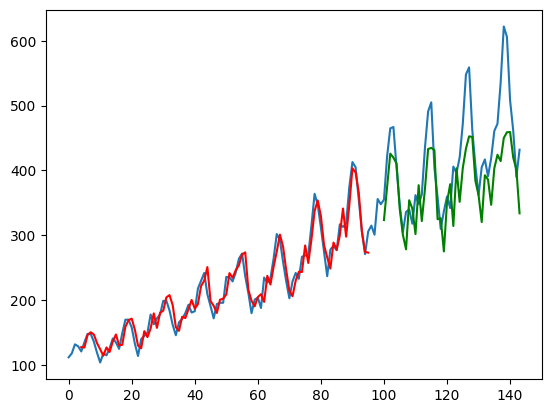

In [22]:
model = AirModel()
optimizer = optim.Adam(model.parameters())
loss_fn = nn.MSELoss()
loader = data.DataLoader(data.TensorDataset(X_train, y_train), shuffle=True, batch_size=8)

n_epochs = 2000
for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # Validation
    if epoch % 100 != 0:
        continue
    model.eval()
    with torch.no_grad():
        y_pred = model(X_train)
        train_rmse = np.sqrt(loss_fn(y_pred, y_train))
        y_pred = model(X_test)
        test_rmse = np.sqrt(loss_fn(y_pred, y_test))
    print("Epoch %d: train RMSE %.4f, test RMSE %.4f" % (epoch, train_rmse, test_rmse))

with torch.no_grad():
    # shift train predictions for plotting
    train_plot = np.ones_like(timeseries) * np.nan
    y_pred = model(X_train)
    y_pred = y_pred[:, -1, :]
    train_plot[lookback:train_size] = model(X_train)[:, -1, :]
    # shift test predictions for plotting
    test_plot = np.ones_like(timeseries) * np.nan
    test_plot[train_size+lookback:len(timeseries)] = model(X_test)[:, -1, :]
# plot
plt.plot(timeseries)
plt.plot(train_plot, c='r')
plt.plot(test_plot, c='g')
plt.show()